# **Sesión 3:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [1]:
import cv2
print("OpenCV should be 4.8.0.76 Current version:", cv2.__version__)
from typing import List
import numpy as np
import imageio
import copy
import glob
import matplotlib.pyplot as plt
from typing import Optional
from utils import *
import os

OpenCV should be 4.8.0.76 Current version: 4.8.0


## **Apartado A:** Filtro Gaussiano y Detección de bordes: Sobel y Canny

El objetivo de este apartado es detectar los bordes de las imágenes de la carpeta ``data/partA-B``. Para ello, deberá seguir los siguientes pasos:

1. **Tarea A.1.** Defina el método ``gaussian_blur()`` que aplique un filtro gausiano para obtener imágenes borrosas. Siga todas las indicaciones del enunciado.
2. **Tarea A.2.** Aplique el método ``gaussian_blur()`` a todas las imágenes en ``data/partA-B``.


3. **Tarea A.3.** Defina la función ``sobel_edge_detector()`` que detecte bordes con el método Sobel. Siga todas las indicaciones del enunciado.
4. **Tarea A.4.** Aplique el método ``sobel_edge_detector()`` a todas las imágenes en ``data/partA-B``.


5. **Tarea A.5.** Defina la función ``canny_edge_detector()`` que detecte bordes con el método Canny. Siga todas las indicaciones del enunciado.
6. **Tarea A.6.** Aplique el método ``canny_edge_detector()`` a todas las imágenes en ``data/partA-B``.

In [2]:
# Nos definimos esta función auxiliar que nos facilitará mostrar imágenes más adelante
def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)  # Mostramos la imagen, poniendole el nombre correspondiente a la ventana desplegada
    cv2.waitKey(0)  # Ponemos una tecla para eliminar la ventana y pasar a la siguiente imagen o terminar la visualización
    cv2.destroyAllWindows()

In [3]:
# Nos definimos esta función auxiliar que nos facilitará cargar y leer imágenes más adelante
def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

In [4]:
def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)  # creamos el path donde vamos a guardar la imagen
    os.makedirs(output_folder, exist_ok=True)
    cv2.imwrite(img_path, img)  # guardamos la imagen en su correspondiente ubicación

### **Tarea A.1:** Defina el método ``gaussian_blur()`` que aplique un filtro gausiano para obtener imágenes borrosas.

In [5]:
# TODO Define the method
def gaussian_blur(img: np.array, sigma: float, filter_shape: Optional[List] = None, verbose: bool = False) -> np.array:
    # TODO If not given, compute the filter shape 

    # Para evitar aplicar ningun filtro gaussiano (útil para comparar imágenes con y sin ruido de apartados posteriores)
    if sigma == 0:
        if verbose:
            show_image(img=img, img_name=f"Gaussian Blur: Sigma = {sigma}")
        return None, img.astype(np.uint8)

    else:
        # Dependiendo de si el parámetro del tamaño del kernel se pasa como parámetro o no, sacamos las dimensiones del kernel de una o de otra forma
        if filter_shape == None:
            k = max(3, int(6*sigma + 1))  # en caso de no tener el tamaño del kernel, lo sacamos en función de la sigma del kernel
            if k % 2 == 0:
                k += 1  # Nos aseguramos de que sea un valor impar
            kh,kw = k,k

        else:  # En caso de sí disponer del tamaño del kernel, simplemente lo cogemos
            kh, kw = int(filter_shape[0]), int(filter_shape[1])
            if kh // 2 == 1: kh +=1
            if kw // 2 == 1: kw += 1  # Nos aseguramos de que sea un valor impar

        # TODO Create the filter coordinates matrices
        cy,cx = kh // 2, kw // 2
        y, x = np.mgrid[-cy:kh-cy, -cx:kw-cx]  # la función de np.mgrid genera dos arrays 2D con los índices de cada coordenada
        
        # TODO Define the formula that goberns the filter
        # formula = (1 / (2*np.pi*sigma**2))*np.exp(-(x**2+y**2)/(2*sigma**2))  # Definimos la fórmula de la Gaussiana pero aún no la hemos normalizado
        formula = np.exp(-(x**2+y**2)/(2*sigma**2))  # Definimos la fórmula de la Gaussiana pero aún no la hemos normalizado
        
        gaussian_filter = (formula / formula.sum()).astype(np.float32) # Aseguramos que la suma sea 1 (normalizando) para que la convolución no cambie el brillo global
        
        # TODO Process the image
        gb_img = cv2.filter2D(img, -1, gaussian_filter)  # Aplicamos el filtro gaussiano de blurreado a la imagen que se nos había pasado como parámetro
        
        if verbose:
            show_image(img=gb_img, img_name=f"Gaussian Blur: Sigma = {sigma}")
        
        # Devolvemos tanto el filtro gaussiano de blurreado que hemos generado, como la imagen a la que se lo hemos aplicado
        return gaussian_filter, gb_img.astype(np.uint8)

### **Tarea A.2.** Aplique el método ``gaussian_blur()`` a todas las imágenes en ``data``.

In [6]:
imgs_gen_path = '../data/partA-B/*.jpg' # Patrón que cumplen todos los paths de los archivos de imágenes de la carpeta data/partA-B
imgs_path = sorted(glob.glob(imgs_gen_path))  # Cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs = load_images(imgs_path)  # Le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_path

['../data/partA-B\\000.jpg',
 '../data/partA-B\\001.jpg',
 '../data/partA-B\\002.jpg',
 '../data/partA-B\\003.jpg',
 '../data/partA-B\\004.jpg',
 '../data/partA-B\\005.jpg']

In [7]:
# # Mostramos las imágenes recién cargadas sin aplicarles nada
for i, img in enumerate(imgs):
    show_image(img = img, img_name = f"Image_{i}")

In [8]:
# TODO Get the gaussian blurred images using a list comprehension
gauss_sigma = 1.4   # Decidimos usar un valor de sigma moderado que consiga aplicar el blur sin llegar a perder demasiada información de la imagen
# Además es el valor que se usa en el ejemplo de las diapositivas del tema 3, por lo que lo usamos como referencia
gb_imgs = [gaussian_blur(img,gauss_sigma,None,False)[1] for img in imgs]  # Aplicamos el filtro a cada imagen y guardamos el resultado

# Queremos blurrear para quitar el ruido y seguir procesando la imagen, ese es el objetivo de este primer paso con el filtro gaussiano

In [9]:
# Mostramos los resultados de las imágenes que hemos blurreado con el filtro Gaussiano
for i, img in enumerate(gb_imgs):
    show_image(img = img, img_name = f"Blurred_Image_{i}")

In [10]:
output_folder = "output_folder/blurred_images"
for i in range((len(gb_imgs))):
    img_name = f"blur_{i}.png"
    write_image(output_folder=output_folder, img_name=img_name, img=gb_imgs[i])

### **Tarea A.3:** Defina la función ``sobel_edge_detector()`` que detecte bordes con el método Sobel.

In [11]:
# TODO Define the method

def sobel_edge_detector(img: np.array, filter: np.array, gauss_sigma: float, gauss_filter_shape: Optional[List] = None, verbose: bool = False) -> np.array:
    # TODO Transform the img to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    # TODO Get a blurry img to improve edge detections
    blurred = gaussian_blur(img=gray_img, sigma=gauss_sigma, filter_shape=gauss_filter_shape, verbose=verbose)[1]
    # Accedemos al índice 1 ya que recordemos que la función de gaussian_blur devuelve el filtro usado y la imagen resultado
    
    # Re-scale
    blurred = blurred/255
    # Estandarizamos antes de calcular derivadas y ángulos ya que queremos trabajar siempre con magnitudes comparables y mantener esa consistencia
    
    # TODO Get vertical edges
    v_edges = cv2.filter2D(blurred, -1, filter)  # Usamos el filtro "filter" para obtener los bordes verticales
    
    # TODO Transform the filter to get the orthogonal edges
    filter = filter.T # para obtener el filtro de bordes horizontales, solo tenemos que trasponer el filtro que teníamos para los verticales
    
    # TODO Get horizontal edges
    h_edges = cv2.filter2D(blurred, -1, filter)
    
    # TODO Get edges
    # Calculamos la magintud del gradiente en cada punto, como la suma de los cuadrados del gradiente horizontal y del vertical
    sobel_edges_img = np.hypot(v_edges, h_edges)  
    # Cuanto mayor sea el gradiente en ese punto, es que el cambio de intensidad es mayor y con más probabilidad sea un borde 
    
    # Get edges angle
    theta = np.arctan2(h_edges, v_edges) # Calculamos el ángulo usando la arcotangente de la parte vertical entre la horizontal
    # para posteriores etapas, nos es útil conocer la dirección/orientación en la que va el gradiente, es decir en la que cambia la intensiad    

    # Visualize if needed
    if verbose:
        show_image(img=sobel_edges_img, img_name="Sobel Edges")
    
    # La función de squeeze elimina posibles ejes de longitud 1 que se nos hayan quedado por ahí al hacer operaciones con los arrays
    return np.squeeze(sobel_edges_img), np.squeeze(theta)

### **Tarea A.4.** Aplique el método ``sobel_edge_detector()`` a todas las imágenes en ``data``.

In [12]:
# TODO Define a sigma value
gauss_sigma = 1.4

# TODO Define the Sobel filter
sobel_filter = np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado (es el que se usa para detectar bordes verticales)


# TODO Get the edges detected by Sobel using a list comprehension
sobel_edges_imgs = [sobel_edge_detector(img=img, filter=sobel_filter, gauss_sigma=gauss_sigma, gauss_filter_shape=None, verbose=False)[0]
                    for img in imgs]

In [13]:
# Mostramos los resultados de las imágenes a las que hemos aplicado el detector de bordes de Sobel
for i, img in enumerate(sobel_edges_imgs):
    show_image(img = img, img_name = f"Edge_Detection_Sobel_Image_{i}")


In [14]:
# Guardamos las imágenes con los bordes detectados por Sobel, PERO NO SE GUARDAN BIEN NS PQ
output_folder = "output_folder/sobel_edges"
for i, img in enumerate(sobel_edges_imgs):
    img_name = f"sobel_{i}.png"
    write_image(output_folder=output_folder, img_name=img_name, img=img)

### Constante de estandarización:

En el enunciado de la práctica no se especifica como tal, ya que se nos indica que utilicemos un filtro de sobel que no está estandarizado, por eso los bordes salen tan remarcados y con valores de blancos muy intensos. No obstante, si seguimos la teoría que aparece en las diapositivas que vemos en clase, tenemos que añadir multiplicando al filtro un valor de $1/8$ para estandarizar.

Si hacemos esta modificación, obtenemos resultados notablemente distintos a nivel de intensidad del blanco de los bordes, pero siguen siendo los mismos bordes:

In [15]:
# Repetimos el mismo proceso pero añadiendo la constante de estandarización
sobel_filter_standard = (1/8)*np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado pero ahora estandarizado

sobel_edges_imgs_standard = [sobel_edge_detector(img=img, filter=sobel_filter_standard, gauss_sigma=gauss_sigma, gauss_filter_shape=None, verbose=True)[0]
                    for img in imgs]

### **Tarea A.5:** Defina la función ``canny_edge_detector()`` que detecte bordes con el método Canny.

In [16]:
# TODO Define the method
def canny_edge_detector(img: np.array, sobel_filter: np.array, gauss_sigma: float, gauss_filter_shape: Optional[List] = None, verbose: bool = False):
    # TODO Call the method sobel_edge_detector()
    sobel_edges_img, theta = sobel_edge_detector(img=img, filter=sobel_filter, gauss_sigma=gauss_sigma, gauss_filter_shape=gauss_filter_shape, verbose=verbose)
    
    # TODO Use NMS to refine edges
    canny_edges_img = non_max_suppression(img=sobel_edges_img, theta=theta)  
    # La función de non max supression (utils.py) nos proporciona una imagen que ya tiene los bordes detectados, pero aún más refinados
    
    if verbose:
        show_image(canny_edges_img, img_name="Canny Edges")
        
    return canny_edges_img

### **Tarea A.6.** Aplique el método ``canny_edge_detector()`` a todas las imágenes en ``data``.

In [17]:
# TODO Define Sobel filter
sobel_filter = np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado (es el que se usa para detectar bordes verticales)

# TODO Define a sigma value for Gauss
gauss_sigma = 1.4

# TODO Define a Gauss filter shape
gauss_filter_shape = None

# TODO Get the edges detected by Canny using a list comprehension
canny_edges = [canny_edge_detector(img=img, sobel_filter=sobel_filter, gauss_sigma=gauss_sigma, gauss_filter_shape=gauss_filter_shape, verbose=True)
               for img in imgs]

In [18]:
# Mostramos los resultados de las imágenes a las que hemos aplicado el detector de bordes de Canny
for i, img in enumerate(canny_edges):
    show_image(img = img, img_name = f"Edge_Detection_Canny_Image_{i}")


In [19]:
output_folder = "output_folder/canny_edges"
for i, img in enumerate(canny_edges):
    img_name = f"canny_{i}.png"
    write_image(output_folder=output_folder, img_name=img_name, img=img)

### Constante de estandarización:

En el enunciado de la práctica no se especifica como tal, ya que se nos indica que utilicemos un filtro de sobel que no está estandarizado, por eso los bordes salen tan remarcados y con valores de blancos muy intensos. No obstante, si seguimos la teoría que aparece en las diapositivas que vemos en clase, tenemos que añadir multiplicando al filtro un valor de $1/8$ para estandarizar.

Si hacemos esta modificación, obtenemos resultados notablemente distintos a nivel de intensidad del blanco de los bordes, pero siguen siendo los mismos bordes:

In [20]:
# TODO Define Sobel filter
sobel_filter_standard = (1/8)*np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado (es el que se usa para detectar bordes verticales)

# Repetimos el mismo proceso pero añadiendo la constante de estandarización
sobel_filter_standard = (1/8)*np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado pero ahora estandarizado

canny_edges_standard = [canny_edge_detector(img=img, sobel_filter=sobel_filter_standard, gauss_sigma=gauss_sigma, gauss_filter_shape=gauss_filter_shape, verbose=True)
               for img in imgs]


### **Pregunta A.1:** Añada ruido a las imágenes de la carpeta ``data``. Compare los resultados que obtiene al aplicar su filtro Sobel con y sin filtro Gausiano.

In [21]:
# # TODO Homework

# Nos creamos una función que automáticamente añade ruido gaussiano a las imágenes
def add_gaussian_noise(img, mean=0, sigma=25):
    noisy = img + np.random.normal(mean, sigma, img.shape)
    noisy = np.clip(noisy, 0, 255).astype(np.uint8)  # Aseguramos que los valores se queden en un rango válido
    return noisy

# Probamos a aplicar la función a una de nuestras imágenes
noisy_gauss = add_gaussian_noise(imgs[0], sigma=16)
show_image(noisy_gauss)


In [22]:
# Creamos nuestra lista de imágenes con ruido
noisy_images = [add_gaussian_noise(img=img, sigma=16) for img in imgs]

# Mostramos los resultados de las imágenes a las que hemos aplicado la función de añadir ruido
for i, img in enumerate(noisy_images):
    show_image(img = img, img_name = f"Noisy_Image_{i}")

output_folder = "output_folder/noisy_images"
for i, img in enumerate(noisy_images):
    img_name = f"noisy_{i}.png"
    write_image(output_folder=output_folder, img_name=img_name, img=img)

In [23]:
# Aplicamos el filtro de sobel a la lista de imágenes ruidosas pero con y sin filtro gaussiano (para blurrear)

# Sigma para cuando sí que aplicamos el filtro gaussiano
sigma_with_gaussian_filter = 1

# Sigma para cuando no aplicamos el filtro gaussiano
sigma_without_gaussian_filter = 0

# Filtro de Sobel que vamos a usar
sobel_filter = np.array([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]], dtype=np.float32)   # Usamos el kernel indicado en el enunciado (es el que se usa para detectar bordes verticales)


In [24]:
# Bordes detectados por Sobel usando el filtro gaussiano
sobel_edges_noisy_imgs_with_gaussian_filter = [sobel_edge_detector(img=img, filter=sobel_filter, 
                                                                   gauss_sigma=sigma_with_gaussian_filter, 
                                                                   gauss_filter_shape=None, verbose=False)[0]
                    for img in noisy_images]


In [25]:
# Bordes detectados por Sobel sin usar el filtro gaussiano
sobel_edges_noisy_imgs_without_gaussian_filter = [sobel_edge_detector(img=img, filter=sobel_filter, 
                                                                   gauss_sigma=sigma_without_gaussian_filter, 
                                                                   gauss_filter_shape=None, verbose=False)[0]
                    for img in noisy_images]

In [26]:
# Comprobación
len(sobel_edges_noisy_imgs_with_gaussian_filter) == len(sobel_edges_noisy_imgs_without_gaussian_filter)

True

In [27]:
# Si queremos ver más claramente la comparación entre los bordes detectados de las imágenes con ruido, con y sin filtro gaussiano de suavizado
for i in range(len(sobel_edges_noisy_imgs_with_gaussian_filter)):
    show_image(img = sobel_edges_noisy_imgs_with_gaussian_filter[i], img_name = f"Edge_Detection_With_Gauss_Filter_{i}")
    show_image(img = sobel_edges_noisy_imgs_without_gaussian_filter[i], img_name = f"Edge_Detection_Without_Gauss_Filter_{i}")

Viendo la comparación, parece que cuando no aplicamos el filtro de suavizado gaussiano, se incluyen bordes que quizá no son los principales que queremos obtener, sino otros bordes más "secundarios". Sin embargo, cuando sí que usamos el filtro de suavizado gaussiano, vemos que nos quedamos solo con lo que sería el borde de la figura principal de la imagen.

### Comparación visual bordes con distintos niveles de ruido

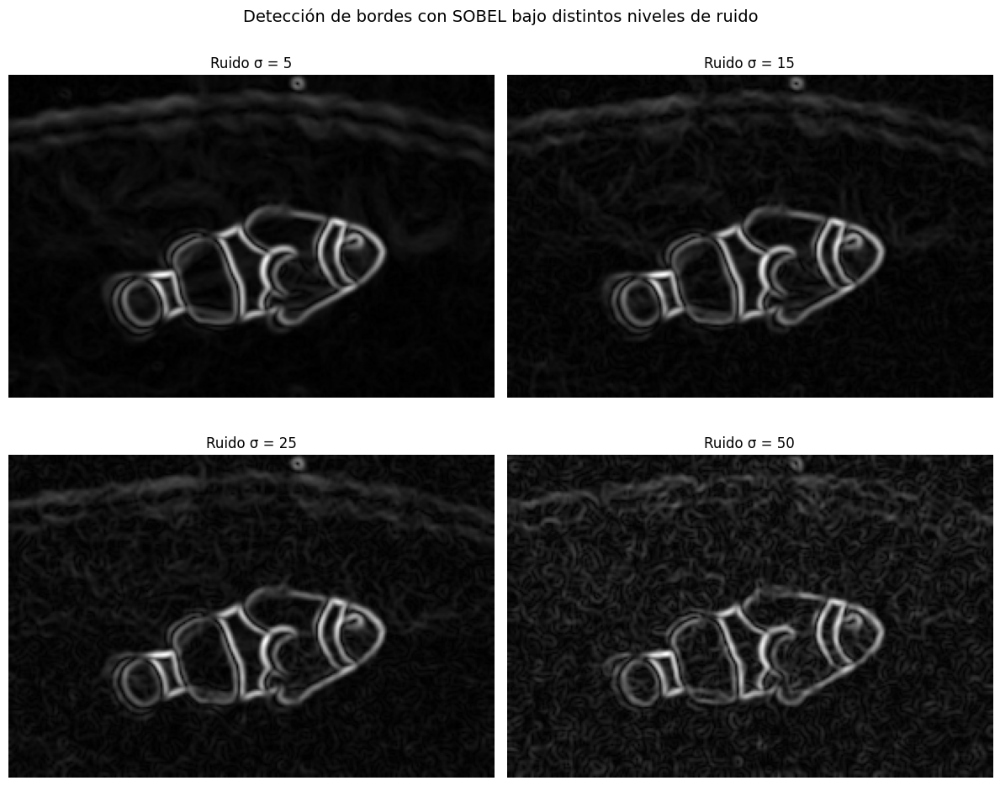

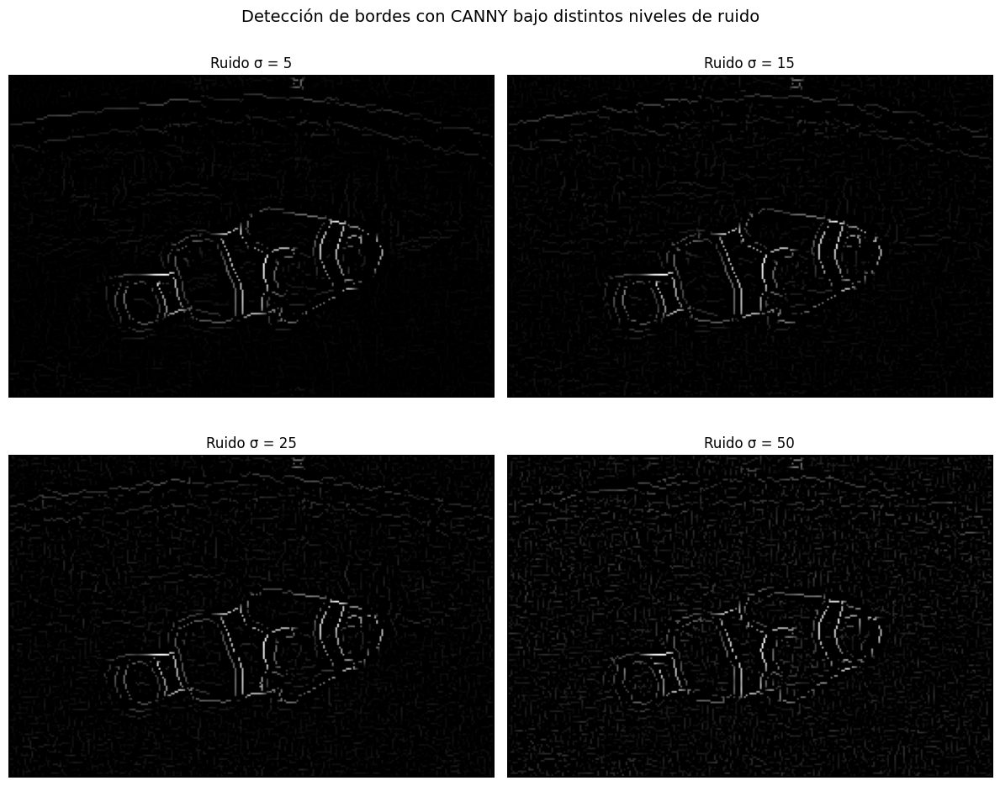

In [28]:
# ============================================================
# COMPARATIVA DE DETECCIÓN DE BORDES (SOBEL Y CANNY)
# BAJO DIFERENTES NIVELES DE RUIDO GAUSSIANO
# ============================================================

# Definimos los valores de sigma del ruido que queremos comparar
noise_sigmas = [5, 15, 25, 50]

# Seleccionamos una imagen base para el experimento
base_img = imgs[3]  

# Definimos el filtro de Sobel
sobel_filter = np.array([[-1, 0, 1],
                         [-2, 0, 2],
                         [-1, 0, 1]], dtype=np.float32)

# Valor del suavizado gaussiano para los detectores
gauss_sigma = 1.4

# ============================================================
# A) COMPARACIÓN SOBEL
# ============================================================

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Detección de bordes con SOBEL bajo distintos niveles de ruido", fontsize=14)

for idx, sigma_noise in enumerate(noise_sigmas):
    # Añadimos ruido gaussiano a la imagen
    noisy_img = add_gaussian_noise(base_img, sigma=sigma_noise)
    
    # Aplicamos Sobel
    sobel_edges, _ = sobel_edge_detector(img=noisy_img, 
                                         filter=sobel_filter, 
                                         gauss_sigma=gauss_sigma,
                                         gauss_filter_shape=None,
                                         verbose=False)
    
    # Mostramos el resultado
    r, c = divmod(idx, 2)
    axs[r, c].imshow(sobel_edges, cmap='gray')
    axs[r, c].set_title(f"Ruido σ = {sigma_noise}")
    axs[r, c].axis("off")

plt.tight_layout()
plt.show()


# ============================================================
# B) COMPARACIÓN CANNY
# ============================================================

fig, axs = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle("Detección de bordes con CANNY bajo distintos niveles de ruido", fontsize=14)

for idx, sigma_noise in enumerate(noise_sigmas):
    # Añadimos ruido gaussiano
    noisy_img = add_gaussian_noise(base_img, sigma=sigma_noise)
    
    # Aplicamos Canny (usando el detector implementado)
    canny_edges_img = canny_edge_detector(img=noisy_img, 
                                          sobel_filter=sobel_filter, 
                                          gauss_sigma=gauss_sigma,
                                          gauss_filter_shape=None,
                                          verbose=False)
    
    # Mostramos el resultado
    r, c = divmod(idx, 2)
    axs[r, c].imshow(canny_edges_img, cmap='gray')
    axs[r, c].set_title(f"Ruido σ = {sigma_noise}")
    axs[r, c].axis("off")

plt.tight_layout()
plt.show()


### **Pregunta A.2:** Utilice la librería ``scikit-image`` y compare el efecto de los filtros Sobel, Canny y Prewitt sobre las imágenes de la carpeta ``data``. ¿Qué diferencias observa entre los filtros? ¿Puede obtener alguna conclusión y/o patrón?

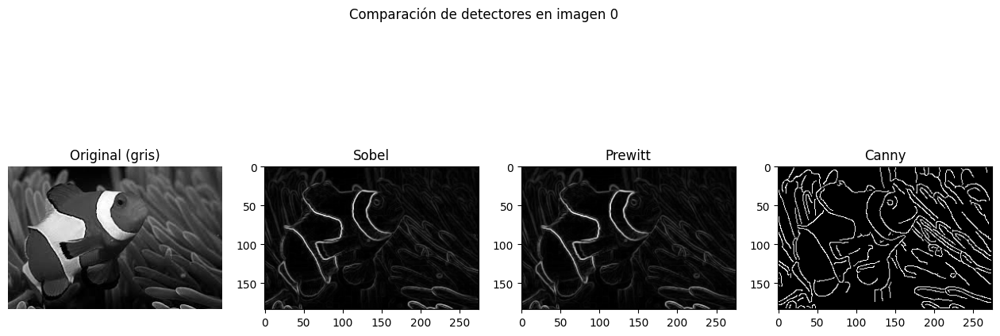

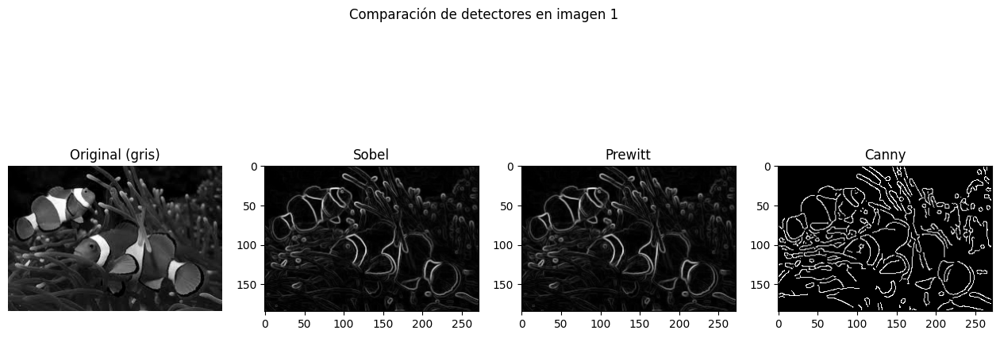

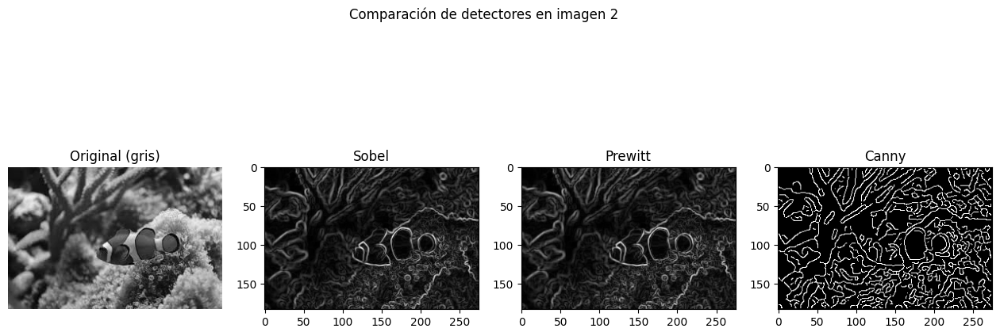

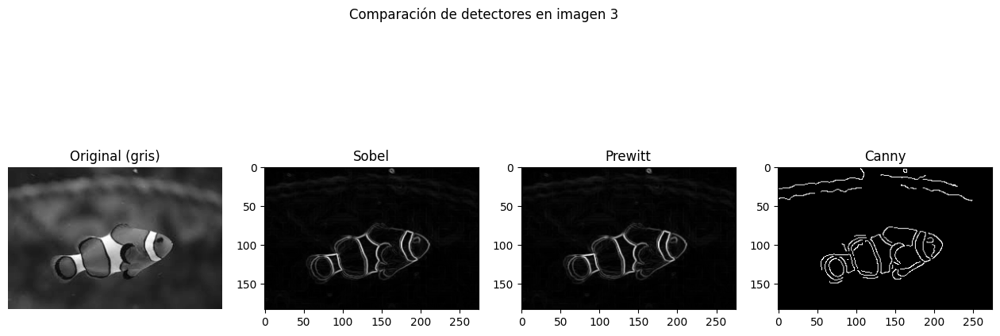

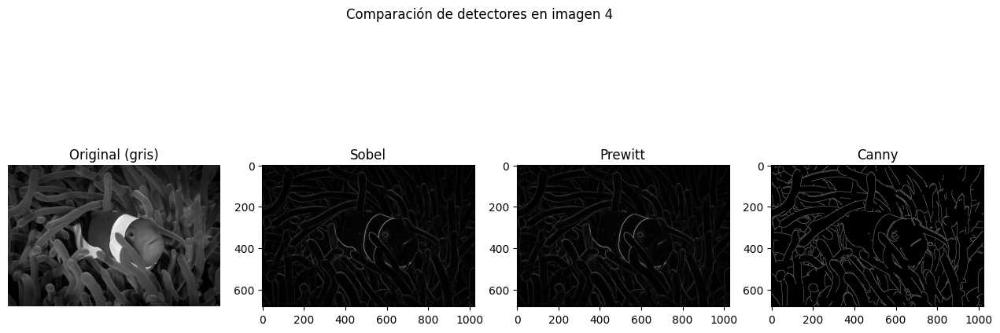

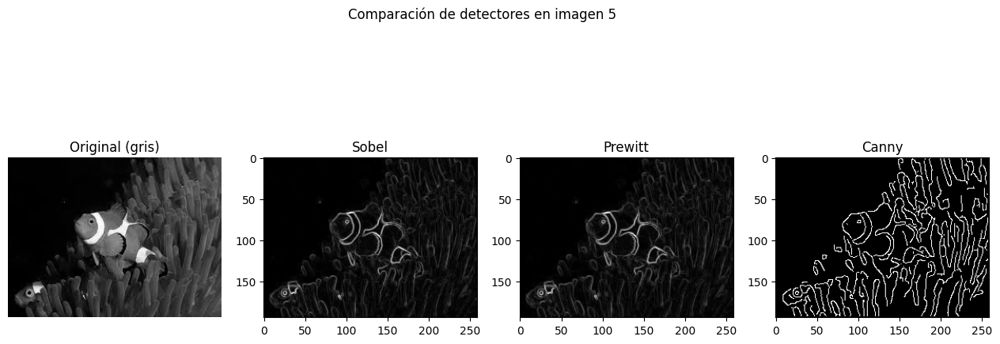

In [29]:
# TODO Homework

# Comparación filtros Sobel, Prewitt y Canny
from skimage import io, color, filters, feature  # 

for i, img in enumerate(imgs):
    # Convertimos a escala de grises para facilitar la detección de bordes
    gray = color.rgb2gray(img)

    # Aplicamos los tres detectores que nos pide el enunciado
    edges_sobel = filters.sobel(gray)      # Gradiente con máscara Sobel
    edges_prewitt = filters.prewitt(gray)  # Gradiente con máscara Prewitt
    edges_canny = feature.canny(gray, sigma=1.5)  # Detector Canny con suavizado interno

    # Mostramos resultados
    fig, ax = plt.subplots(1, 4, figsize=(16, 6))
    ax[0].imshow(gray, cmap='gray'); ax[0].set_title("Original (gris)"); ax[0].axis("off")
    ax[1].imshow(edges_sobel, cmap='gray'); ax[1].set_title("Sobel")
    ax[2].imshow(edges_prewitt, cmap='gray'); ax[2].set_title("Prewitt")
    ax[3].imshow(edges_canny, cmap='gray'); ax[3].set_title("Canny")
    plt.suptitle(f"Comparación de detectores en imagen {i}")
    plt.show()


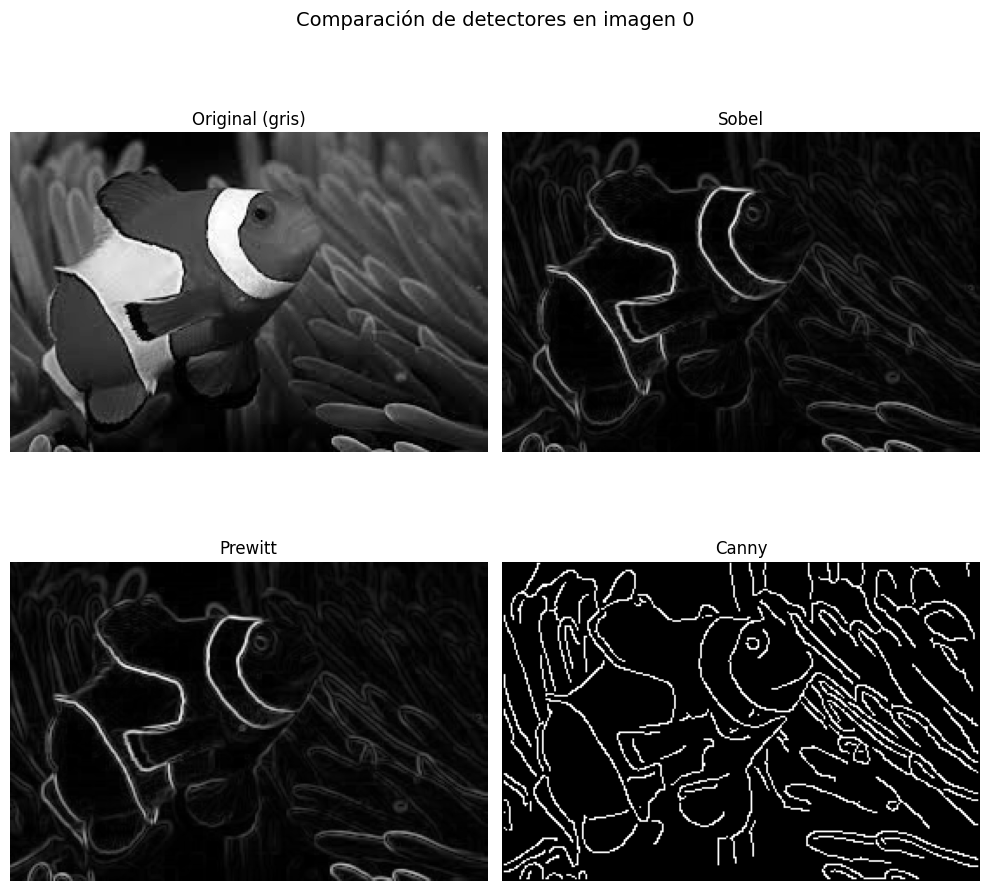

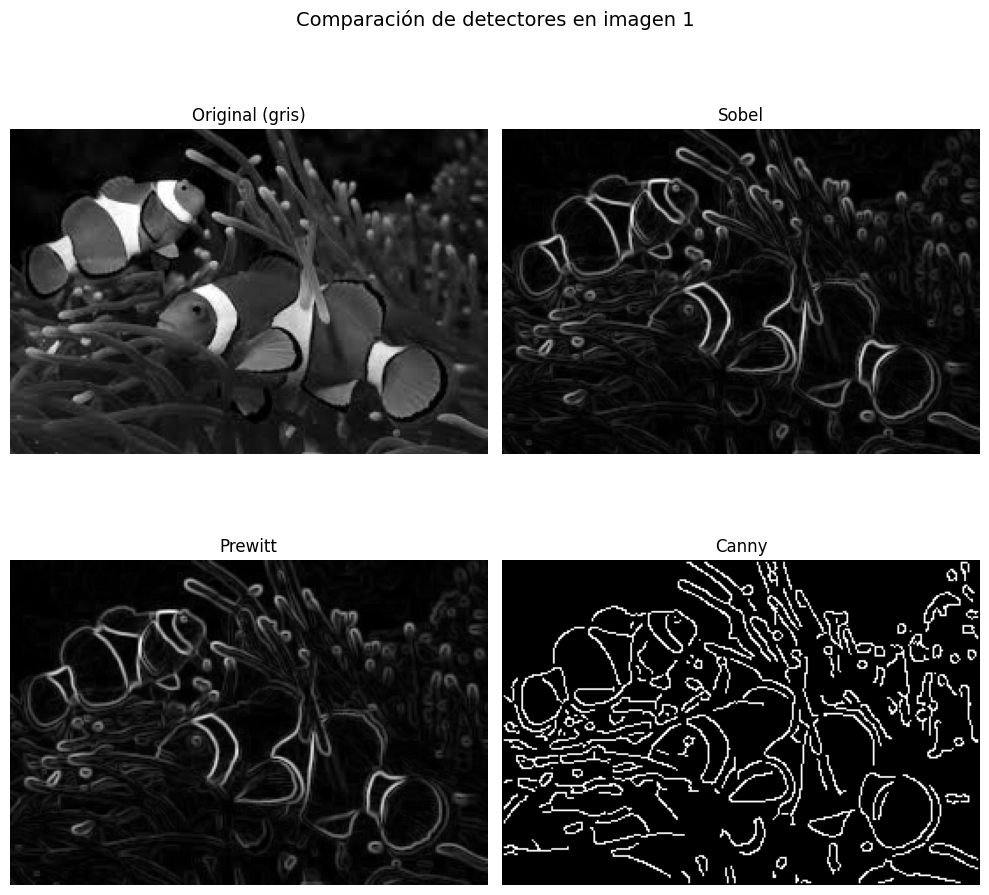

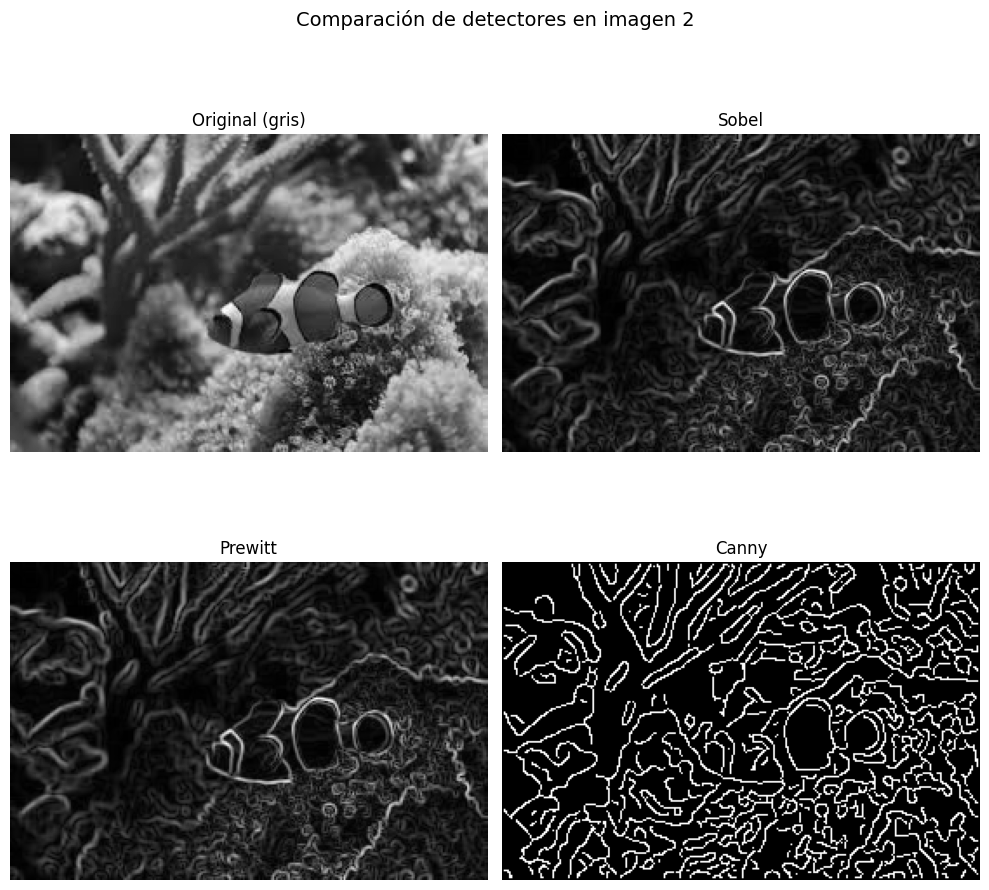

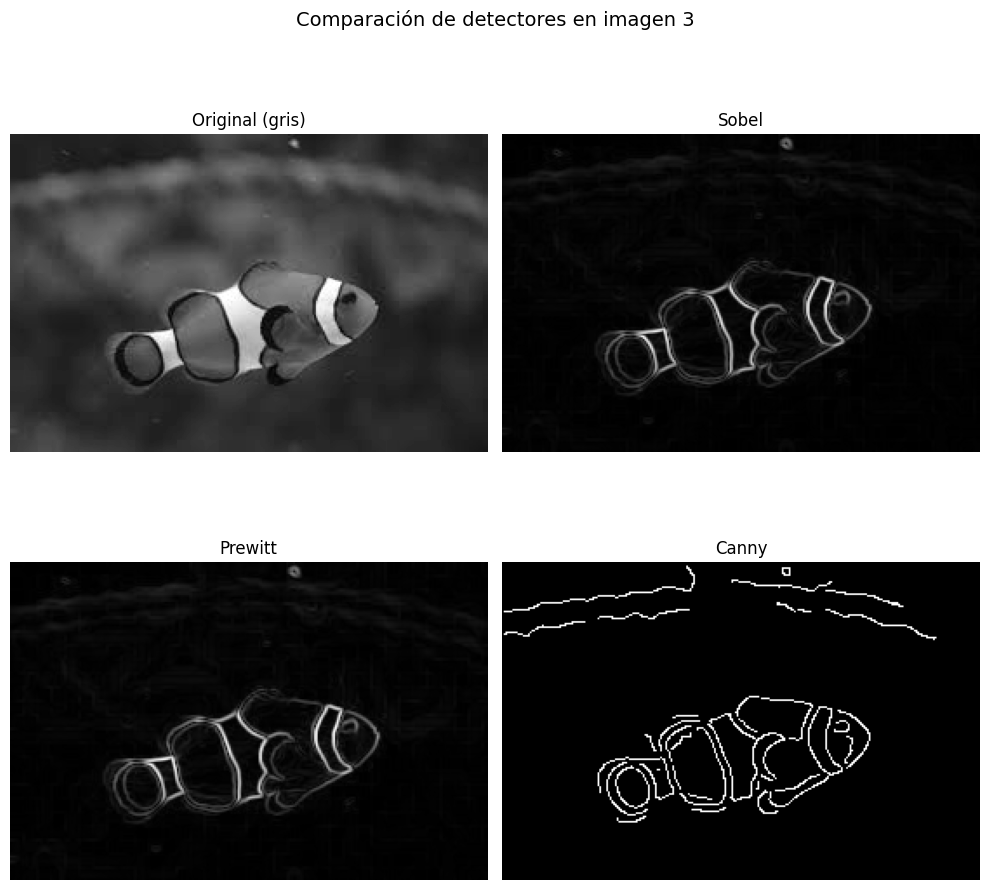

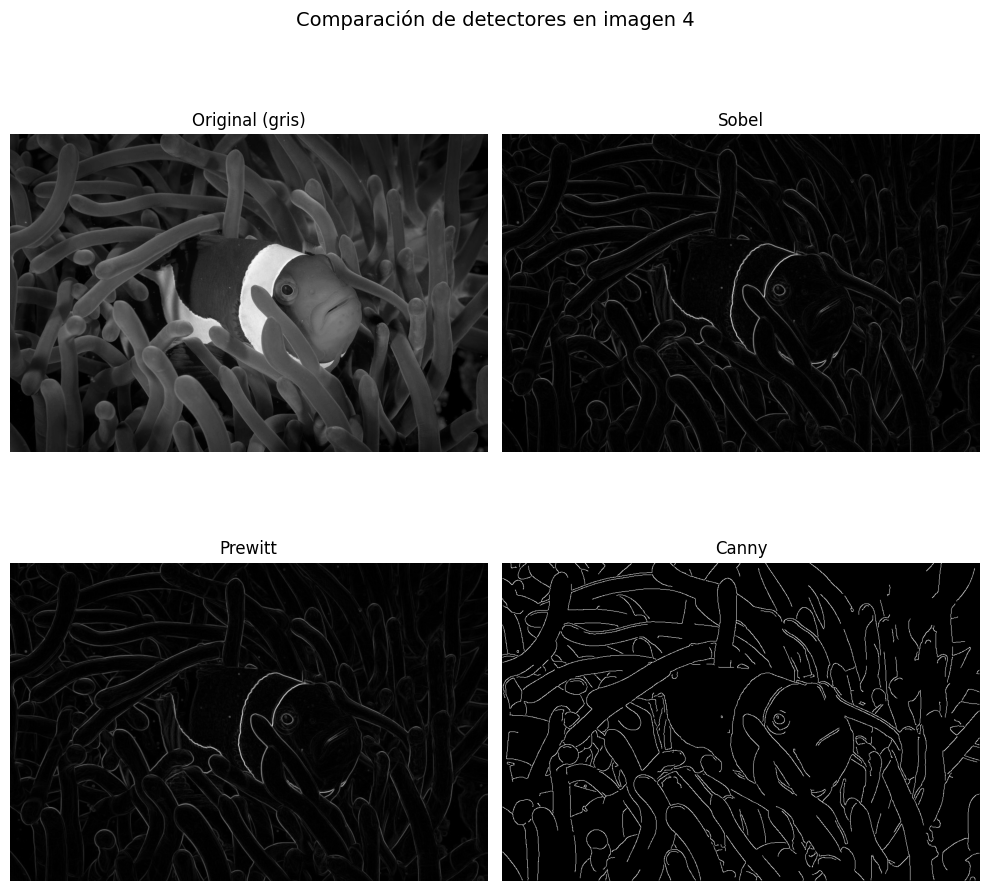

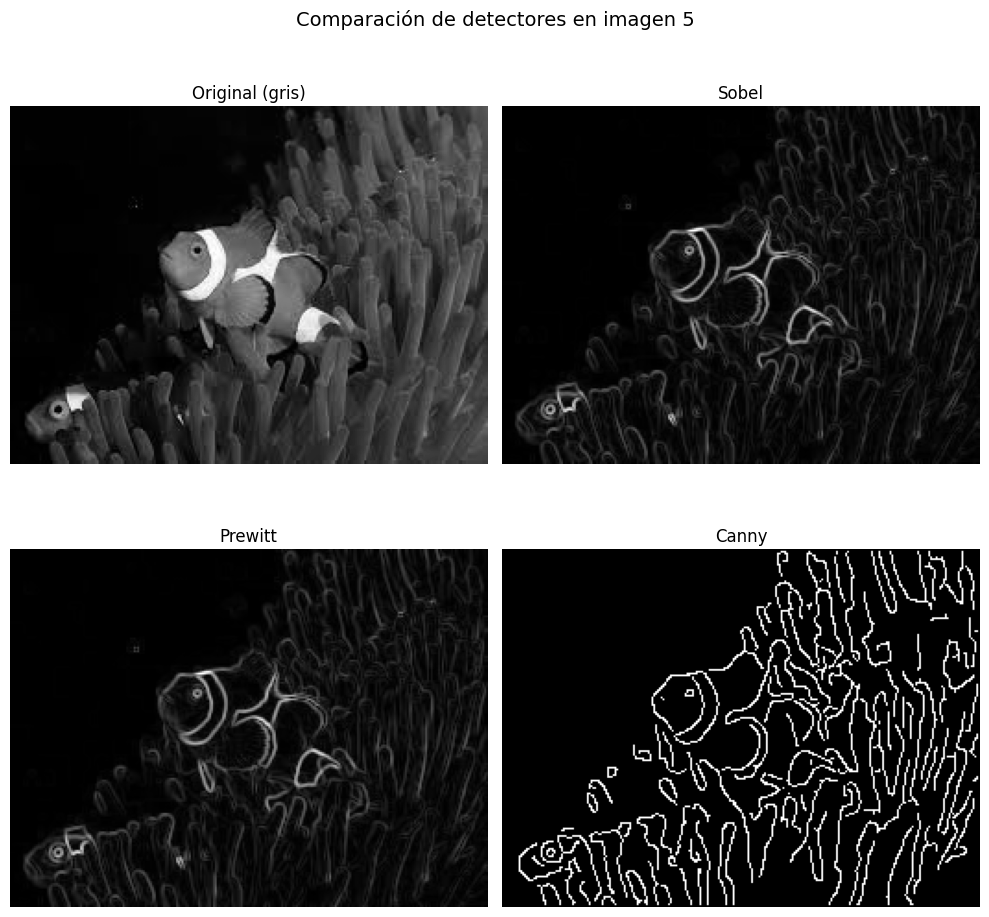

In [30]:
# Repetimos lo mismo pero mostrando los gráficos de otra manera, para que se vean mejor en el informe

for i, img in enumerate(imgs):
    # Convertimos a escala de grises para facilitar la detección de bordes
    gray = color.rgb2gray(img)

    # Aplicamos los tres detectores
    edges_sobel = filters.sobel(gray)      # Gradiente con máscara Sobel
    edges_prewitt = filters.prewitt(gray)  # Gradiente con máscara Prewitt
    edges_canny = feature.canny(gray, sigma=1.5)  # Detector Canny con suavizado interno

    # Creamos una cuadrícula 2x2
    fig, ax = plt.subplots(2, 2, figsize=(10, 10))

    # Primera fila
    ax[0, 0].imshow(gray, cmap='gray')
    ax[0, 0].set_title("Original (gris)")
    ax[0, 0].axis("off")

    ax[0, 1].imshow(edges_sobel, cmap='gray')
    ax[0, 1].set_title("Sobel")
    ax[0, 1].axis("off")

    # Segunda fila
    ax[1, 0].imshow(edges_prewitt, cmap='gray')
    ax[1, 0].set_title("Prewitt")
    ax[1, 0].axis("off")

    ax[1, 1].imshow(edges_canny, cmap='gray')
    ax[1, 1].set_title("Canny")
    ax[1, 1].axis("off")

    plt.suptitle(f"Comparación de detectores en imagen {i}", fontsize=14)
    plt.tight_layout()
    plt.show()


### Conclusiones

Los operadores Sobel y Prewitt ofrecen resultados muy similares, ambos detectan correctamente los contornos principales de las figuras, aunque Sobel produce bordes algo más suaves y menos afectados por el ruido gracias a su ligera ponderación central. Prewitt, al ser más simple, genera bordes más nítidos pero también más irregulares.

El detector Canny proporciona bordes más delgados, continuos y limpios, eliminando gran parte del ruido gracias a su filtrado gaussiano y a la Non-Maximum Suppression. En conjunto, Canny ofrece la detección más precisa y robusta, mientras que Sobel y Prewitt son opciones más rápidas y adecuadas para tareas básicas o imágenes con poco ruido

#### Comparación operadores de Prewwit y Sobel

Usan filtros muy similares pero con una ligera diferencia en cuanto a la mayor o menor ponderación de valores centrales

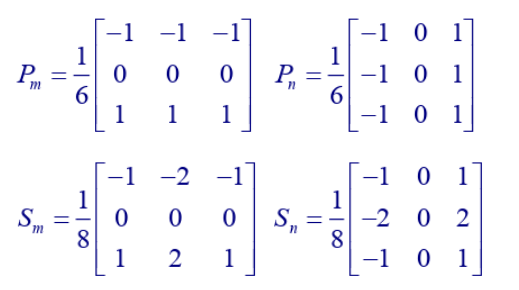

## **Apartado B:** Operadores Morfológicos

Para resolver este partado, deberá seguir los siguientes pasos:

1. **Tarea B.1.** Defina el método ``binarize()`` para binarizar imágenes.
2. **Tarea B.2.** Defina el método ``custom_dilate()``.
3. **Tarea B.3.** Defina el método ``custom_erode()``.
4. **Pregunta B.1** Aplique los métodos ``custom_dilate()`` y ``custom_erode()`` a todas las imágenes de la carpeta ``data``.


### **Tarea B.1.** Defina el método ``binarize()`` para binarizar imágenes.

In [31]:
def binarize(img: np.array, threshold: int = 127):
    # Convertimos a escala de grises si la imagen es RGB
    if len(img.shape)== 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img

    # Aplicamos umbralización manualmente usando numpy
    binary_img = np.where(gray < threshold, 0, 255).astype(np.uint8)
    # Todo lo que es menor que el threshold, lo ponemos como 0, y el resto como 1

    return binary_img

show_image(imgs[0])
show_image(binarize(imgs[0]))


In [32]:
# También se puede hacer usando la función de threshold de cv2

def binarize2(img: np.array, threshold: int = 127):
    # Convertimos a escala de grises si la imagen es RGB
    if len(img.shape)== 3:
        gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    else:
        gray = img

    # Aplicamos umbralización usando threshold
    _, binary_img = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    # Todo lo que es menor que el threshold, se pone como 0, y el resto como 1

    return binary_img

show_image(imgs[0])
show_image(binarize2(imgs[0]))

In [33]:
output_folder = "output_folder/binarized_images"

img_name = f"binary_{0}.png"
write_image(output_folder=output_folder, img_name=img_name, img=binarize2(imgs[0]))

img_name = f"binary_{1}.png"
write_image(output_folder=output_folder, img_name=img_name, img=binarize2(imgs[1]))

### **Tarea B.2.** Defina el método ``custom_dilate()``

In [34]:
# TODO Homework: define the dilation method

# Definimos el tamaño de nuestro kernel, que actuará como elemento estructurante para el operador morfológico de dilatación
kernel_shape = (3,3)
structurant_element = np.ones(shape=kernel_shape).astype(np.uint8)

def custom_dilate(img):

    # Binarizamos la imagen antes de nada (por si acaso nolo está)
    img = binarize(img)

    # TODO pad the original image so it can keep dimensions after processing
    pad_width = int((kernel_shape[0] - 1) / 2)  # investigando en internet sobre cómo se relaciona el tamaño del kernel aplicado y el padding necesario, hallamos esta fórmula

    padded = np.pad(array=img, pad_width=pad_width, mode="mean")  # hacemos padding usando un kernel de (3x3) por lo que tenemos que añadir solo 1 fila y columna tanto arriba como abajo de la imagen
    # si usamos el modo "mean" significa que el valor que se añade de padding será la media de los valores cercanos en ese pixel de la imagen
    
    # TODO get img shape
    width = img.shape[1]
    height = img.shape[0]
    
    # TODO Create an element with the same dimensions as the padded img
    dilated = np.zeros(shape=padded.shape)

    # Preferimos hacer el bucle usando los indices con la referencia ya en la matriz con padding añadido, para verlo más claro
    for j in range(pad_width, pad_width + height):
        for i in range(pad_width, pad_width + width):

            # TODO Add logic to the operation

            # Primero seleccionamos cuál es el área que tenemos que tener en cuenta para esta iteración según nuestro elemento estructurante
            area_involved = padded[j - pad_width:j + pad_width + 1,
                                i - pad_width:i + pad_width + 1]*structurant_element
            # cogemos una matriz de tamaño kernel_shape, centrada en nuestro elemento j,i y luego lo multiplicamos por el elemento estructurante
            
            # Cogemos el máximo de todos los valores de nuestro área seleccionada, ese será el nuevo valor asociado al pixel j,i (dilatado)
            dilated[j, i] = np.max(area_involved)

    # TODO Select the region of interest (ROI). Modify if needed
    dilated = dilated[pad_width:height+1, pad_width:width+1]  # a la hora de devolver la imagen, nos quedamos con lo que no es parte añadida por el padding
    
    return dilated.astype(np.uint8)  # devolvemos la imagen convertida a una matriz de números enteros

In [35]:
# Ejemplo para entender mejor como funciona la función de np.pad()
np.pad(np.array([[1,2,3], [4,5,6]]), pad_width=1, mode="mean")

array([[3, 2, 4, 4, 3],
       [2, 1, 2, 3, 2],
       [5, 4, 5, 6, 5],
       [3, 2, 4, 4, 3]])

### **Tarea B.3.** Defina el método ``custom_erode()``

In [36]:
# TODO Homework: define the erotion method

# Definimos el tamaño de nuestro kernel, que actuará como elemento estructurante para el operador morfológico de dilatación
kernel_shape = (3,3)
structurant_element = np.ones(shape=kernel_shape).astype(np.uint8)

def custom_erode(img):

    # Binarizamos la imagen antes de nada (por si acaso nolo está)
    img = binarize(img)

    # TODO pad the original image so it can keep dimensions after processing
    pad_width = int((kernel_shape[0] - 1) / 2)  # investigando en internet sobre cómo se relaciona el tamaño del kernel aplicado y el padding necesario, hallamos esta fórmula

    padded = np.pad(array=img, pad_width=pad_width, mode="mean")  # hacemos padding usando un kernel de (3x3) por lo que tenemos que añadir solo 1 fila y columna tanto arriba como abajo de la imagen
    # si usamos el modo "mean" significa que el valor que se añade de padding será la media de los valores cercanos en ese pixel de la imagen
    
    # TODO get img shape
    width = img.shape[1]
    height = img.shape[0]
    
    # TODO Create an element with the same dimensions as the padded img
    eroded = np.zeros(shape=padded.shape)

    # Preferimos hacer el bucle usando los indices con la referencia ya en la matriz con padding añadido, para verlo más claro
    for j in range(pad_width, pad_width + height):
        for i in range(pad_width, pad_width + width):

            # TODO Add logic to the operation

            # Primero seleccionamos cuál es el área que tenemos que tener en cuenta para esta iteración según nuestro elemento estructurante
            area_involved = padded[j - pad_width:j + pad_width + 1,
                                i - pad_width:i + pad_width + 1]*structurant_element
            # cogemos una matriz de tamaño kernel_shape, centrada en nuestro elemento j,i y luego lo multiplicamos por el elemento estructurante
            
            # Cogemos el máximo de todos los valores de nuestro área seleccionada, ese será el nuevo valor asociado al pixel j,i (dilatado)
            eroded[j, i] = np.min(area_involved)

    # TODO Select the region of interest (ROI). Modify if needed
    eroded = eroded[pad_width:height+1, pad_width:width+1]  # a la hora de devolver la imagen, nos quedamos con lo que no es parte añadida por el padding
    
    return eroded.astype(np.uint8)  # devolvemos la imagen convertida a una matriz de números enteros


### **Pregunta B.1** Aplique los métodos ``custom_dilate()`` y ``custom_erode()`` a todas las imágenes de la carpeta ``data``.

In [37]:
# TODO Homework

# Imágenes dilatadas
dilated_imgs = [custom_dilate(img) for img in imgs]

# Imágenes erosionadas
eroded_imgs = [custom_erode(img) for img in imgs]

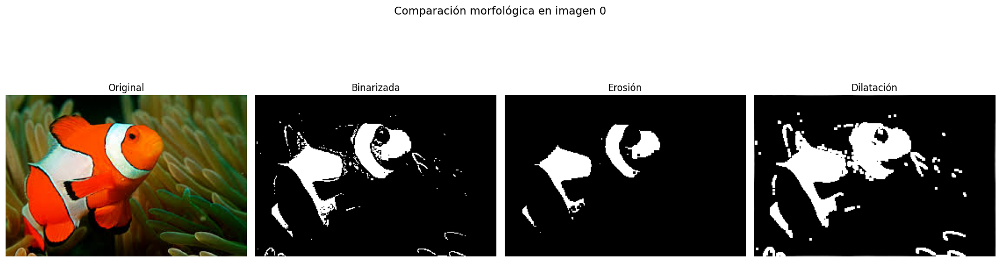

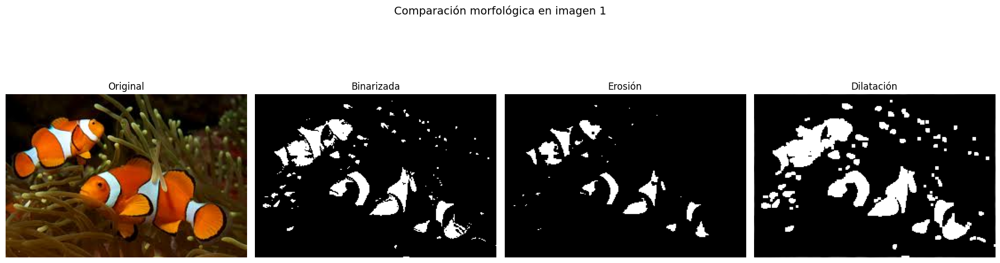

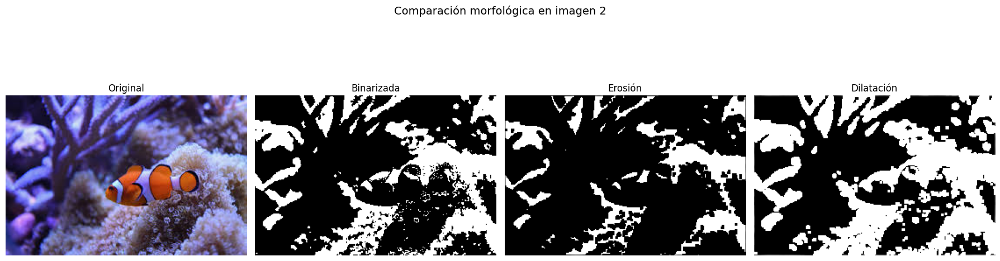

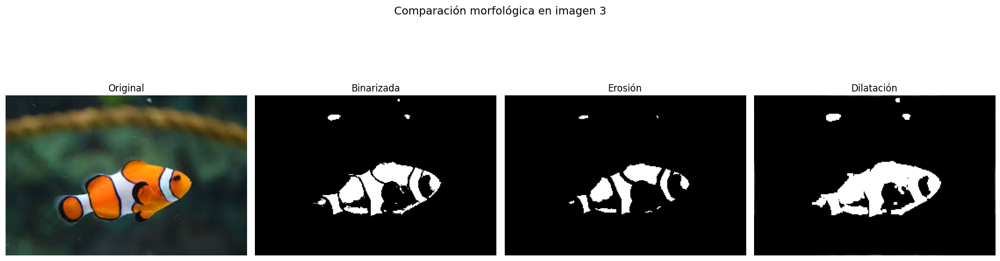

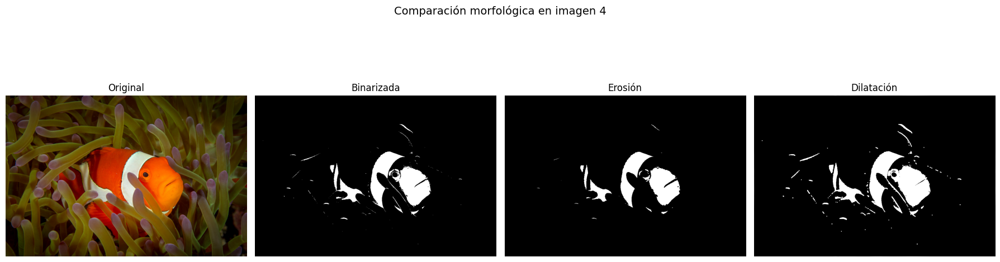

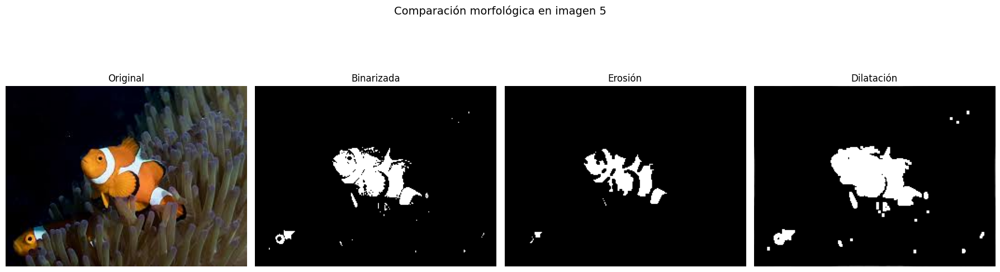

In [38]:
# Generamos las imágenes binarizadas para mostrarlas en la comparación
binary_imgs  = [binarize(img) for img in imgs] 

# Mostramos los resultados comparativos
for i, img in enumerate(imgs):
    fig, ax = plt.subplots(1, 4, figsize=(18, 6))

    # Imagen original
    ax[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[0].set_title("Original")
    ax[0].axis("off")

    # Imagen binarizada
    ax[1].imshow(binary_imgs[i], cmap='gray')
    ax[1].set_title("Binarizada")
    ax[1].axis("off")

    # Imagen erosionada
    ax[2].imshow(eroded_imgs[i], cmap='gray')
    ax[2].set_title("Erosión")
    ax[2].axis("off")

    # Imagen dilatada
    ax[3].imshow(dilated_imgs[i], cmap='gray')
    ax[3].set_title("Dilatación")
    ax[3].axis("off")

    # Título general y ajuste
    plt.suptitle(f"Comparación morfológica en imagen {i}", fontsize=14)
    plt.tight_layout()
    plt.show()


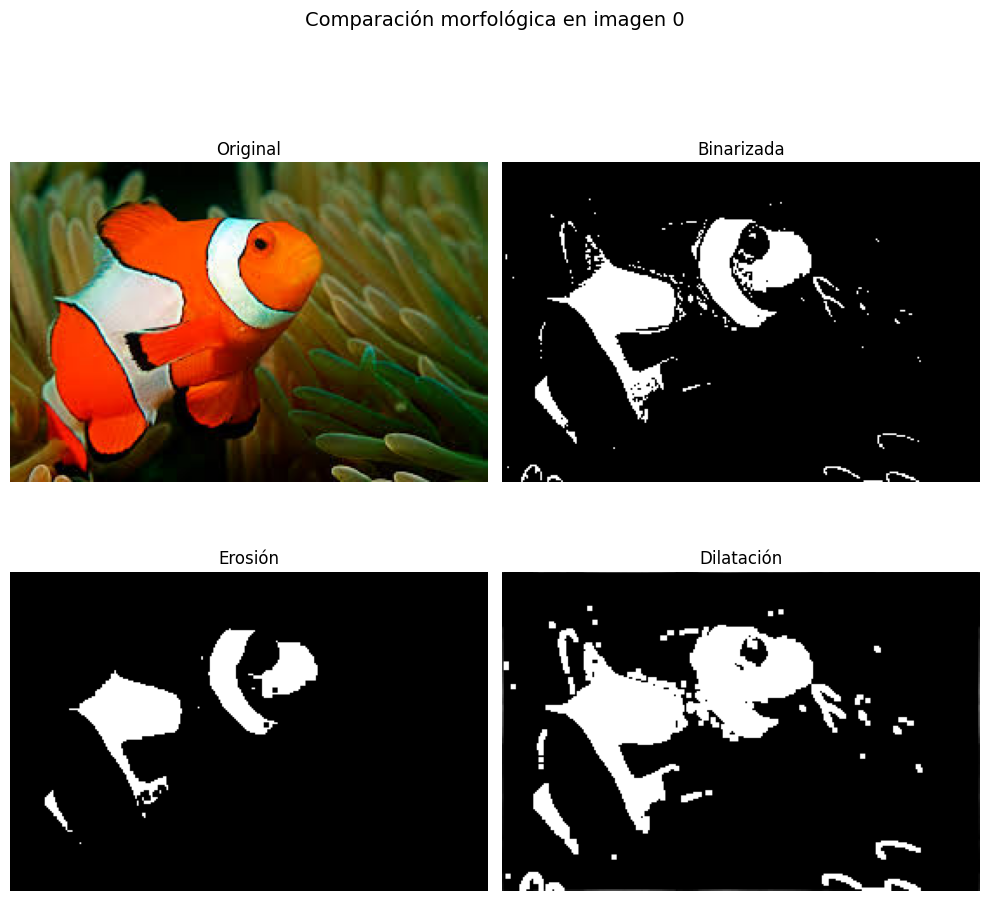

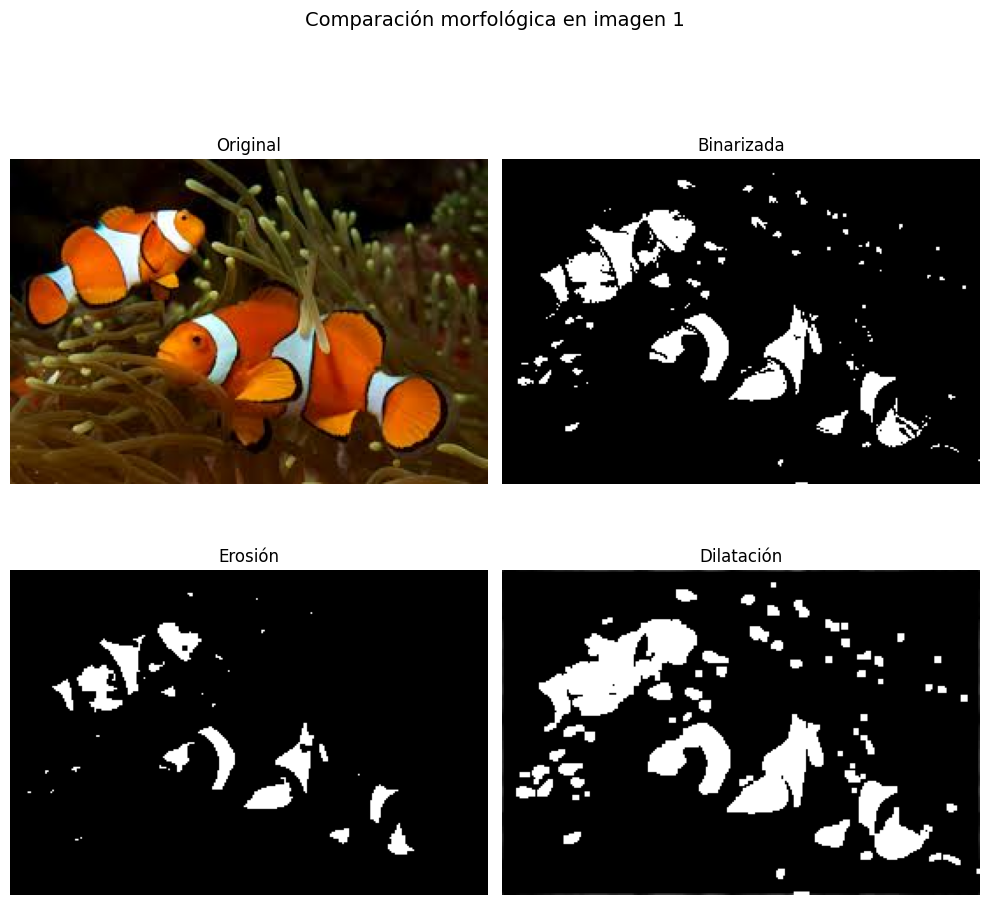

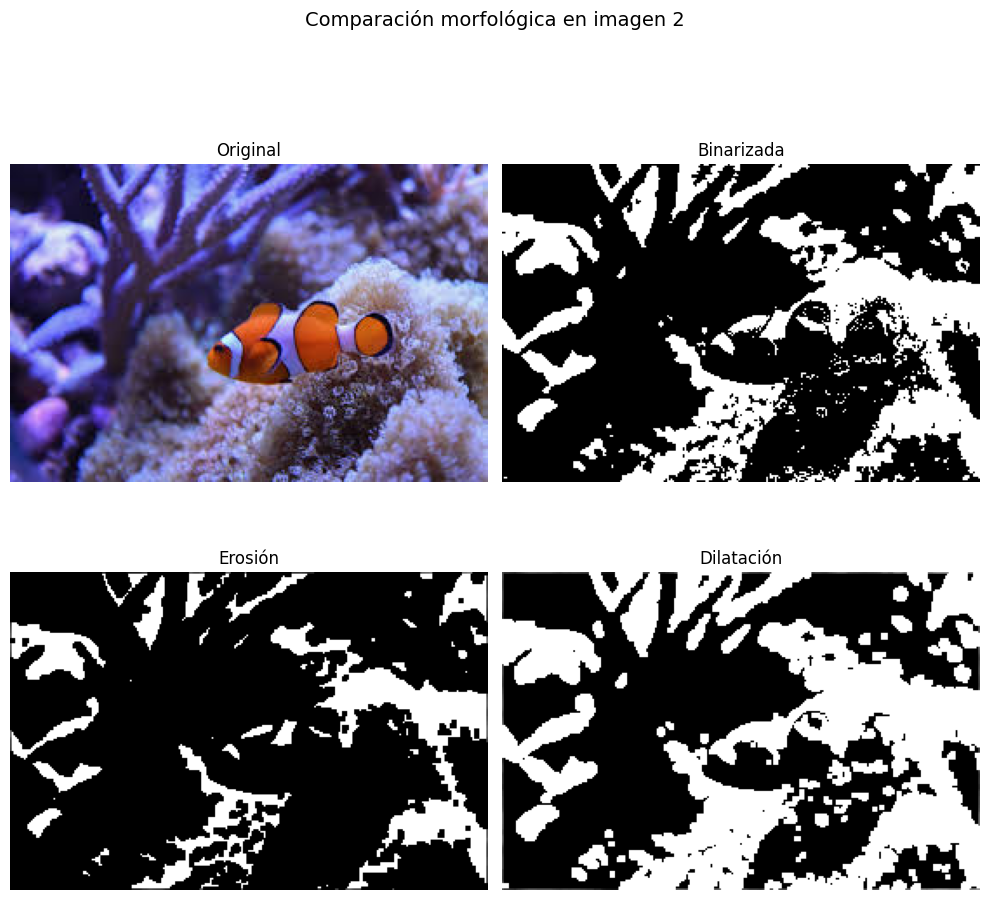

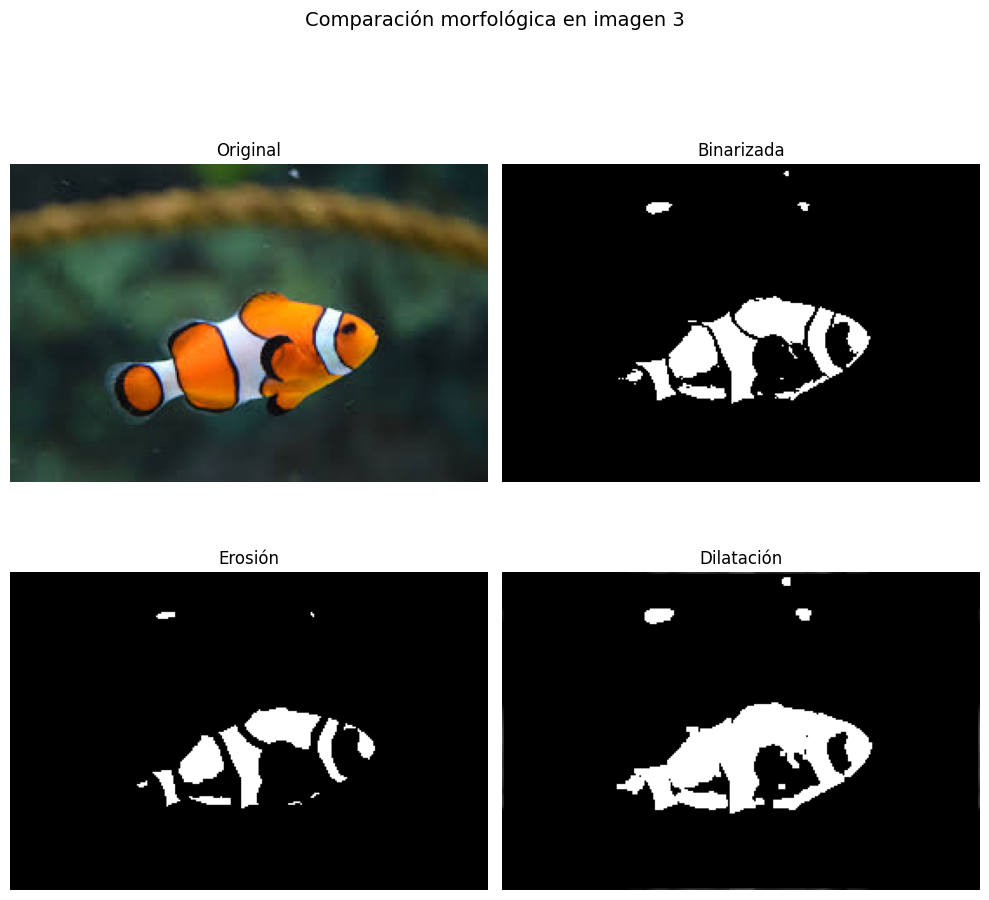

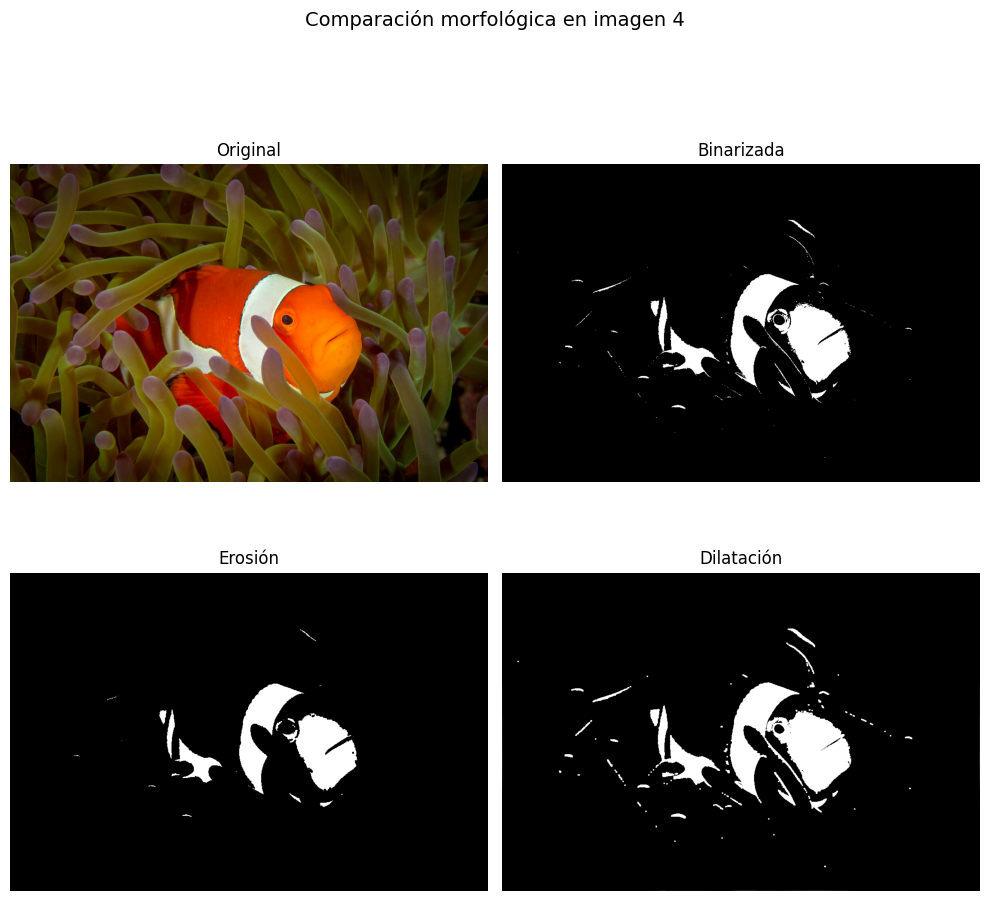

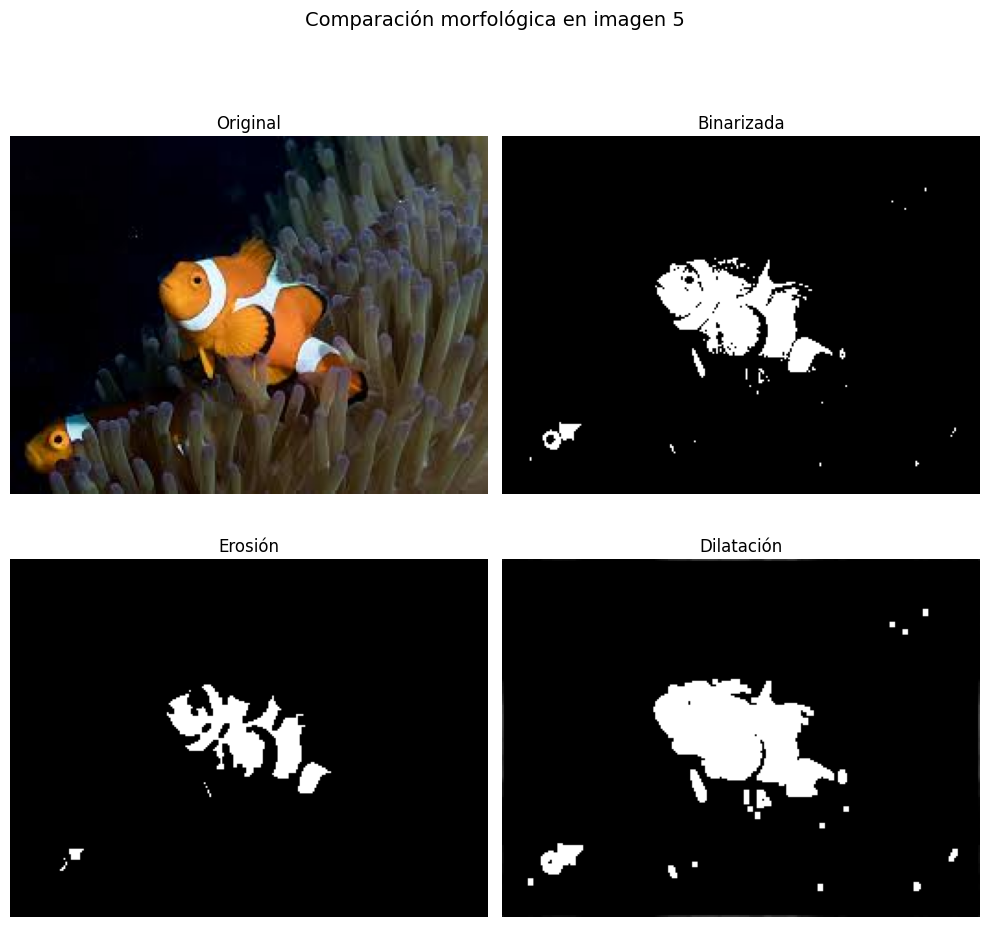

In [39]:
# Repetimos lo mismo pero mostrando los gráficos de otra manera, para que se vean mejor en el informe

for i, img in enumerate(imgs):
    fig, ax = plt.subplots(2, 2, figsize=(10, 10))

    # Imagen original
    ax[0, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax[0, 0].set_title("Original")
    ax[0, 0].axis("off")

    # Imagen binarizada
    ax[0, 1].imshow(binary_imgs[i], cmap='gray')
    ax[0, 1].set_title("Binarizada")
    ax[0, 1].axis("off")

    # Imagen erosionada
    ax[1, 0].imshow(eroded_imgs[i], cmap='gray')
    ax[1, 0].set_title("Erosión")
    ax[1, 0].axis("off")

    # Imagen dilatada
    ax[1, 1].imshow(dilated_imgs[i], cmap='gray')
    ax[1, 1].set_title("Dilatación")
    ax[1, 1].axis("off")

    # Título general y ajuste de márgenes
    plt.suptitle(f"Comparación morfológica en imagen {i}", fontsize=14)
    plt.tight_layout(rect=[0, 0, 1, 0.96])  # deja espacio para el título
    plt.show()
